# 03 · Can machine learning beat Lee-Carter?

Notebook 02 showed that Lee-Carter was overconfident on 2015–2024, and that even a naive per-age trend did better. Here I try gradient boosting, under the same rules:

* **Train** on 1980–2014 only, **test** on 2015–2024 (the same window as notebook 02).
* Choose model settings on an **earlier validation window** (forecast 2005–2014 from 2004). The test years are used once, at the end.
* Score with the same metrics: log RMSE overall and by period, plus bias by age band.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from src.data import load_qx, qx_matrix, qx_to_mx, mx_to_qx
from src.lee_carter import LeeCarter, random_walk_forecast
from src.evaluate import log_rmse, mape, error_by_year
from src.lifetable import e0
from src.ml import ImprovementGBM, FEATURES, GBM_PARAMS, make_features, blend

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#999999", "axes.labelcolor": "#333333",
    "xtick.color": "#666666", "ytick.color": "#666666", "lines.linewidth": 2,
})
MODEL_COLORS = {"Actual": "#333333", "Lee-Carter": "#257de0", "Naive trend": "#00a080",
                "GBM": "#f47230", "GBM + naive": "#8b5cf6"}
FIG_DIR = "../reports/figures"
SEXES = ["male", "female"]

df = load_qx()
q_all = {s: qx_matrix(df, s) for s in SEXES}
m = {s: qx_to_mx(q_all[s].loc[0:100]) for s in SEXES}
log_m = {s: np.log(m[s]) for s in SEXES}

TRAIN_END, H = 2014, 10
test = {s: m[s].loc[:, 2015:2024] for s in SEXES}

## 1. The obvious approach fails: a tree model on (age, year, sex)

The first idea is to feed age, year and sex into a gradient-boosting model and ask for log death rates in 2015–2024. The catch: tree models split the data into ranges and predict an average within each range. Any year after 2014 lands in the same "year ≥ 2014" range, so the forecast is **flat**: it assumes mortality stops improving the day the training data ends.

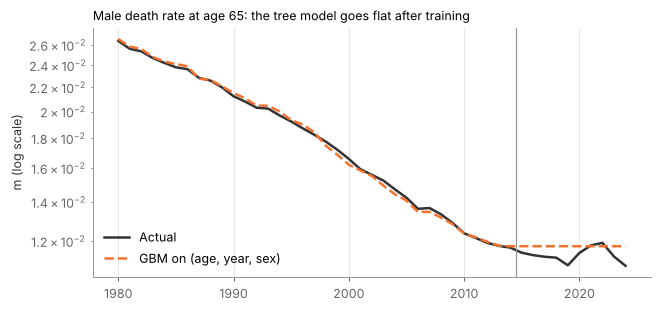

In [2]:
rows = [(s, a, y, log_m[s].loc[a, y]) for s in SEXES for a in log_m[s].index for y in range(1980, TRAIN_END + 1)]
naive_df = pd.DataFrame(rows, columns=["sex", "age", "year", "log_m"]).assign(sex=lambda d: (d.sex == "male").astype(int))
tree = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0)
tree.fit(naive_df[["age", "year", "sex"]], naive_df["log_m"])

age = 65
years = np.arange(1980, 2025)
pred = tree.predict(pd.DataFrame({"age": age, "year": years, "sex": 1}))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(years, m["male"].loc[age, years], color=MODEL_COLORS["Actual"], label="Actual")
ax.plot(years, np.exp(pred), color=MODEL_COLORS["GBM"], ls="--", label="GBM on (age, year, sex)")
ax.axvline(TRAIN_END + 0.5, color="#999999", lw=1)
ax.set_yscale("log")
ax.set_title(f"Male death rate at age {age}: the tree model goes flat after training", loc="left", fontsize=10)
ax.set_ylabel("m (log scale)"); ax.legend(frameon=False)
fig.savefig(f"{FIG_DIR}/ml_flat_extrapolation.png", bbox_inches="tight", dpi=150)

## 2. A better framing: learn how mortality *changes*

Instead of predicting the rate itself, I predict how much the log death rate will move over the next *h* years, using only what was known at the forecast date (code in `src/ml.py`):

| Input | Meaning |
|---|---|
| `age`, `sex` | who |
| `h` | how many years ahead (1–10) |
| `level` | today's log death rate at that age |
| `imp5`, `imp10` | average yearly change over the last 5 and 10 years (smoothed across neighbouring ages) |
| `imp_long` | average yearly change since 1980 |

Each training row is "standing in year *t*, looking *h* years ahead", for every origin from 1990 to 2013 with a target year no later than 2014. A unit test checks that changing data after year *t* doesn't change the inputs, so there is no look-ahead leakage.

In [3]:
gbm_final = ImprovementGBM().fit(log_m, last_year=TRAIN_END)
print("Training rows:", len(gbm_final.X_), " features:", FEATURES)
gbm_final.X_.assign(target=gbm_final.y_).sample(5, random_state=1).round(4)

Training rows: 39390  features: ['age', 'sex', 'h', 'level', 'imp5', 'imp10', 'imp_long']


,age,sex,h,level,imp5,imp10,imp_long,target
38461,81,0,1,-3.1833,-0.0215,-0.0193,-0.0127,-0.0195
21718,3,0,1,-8.2547,-0.0536,-0.0338,-0.0400,-0.0801
15234,84,1,1,-2.3397,-0.0230,-0.0189,-0.0120,-0.0428
9676,81,1,6,-2.4782,-0.0110,-0.0122,-0.0105,-0.1773
6715,49,1,7,-5.6167,-0.0196,-0.0250,-0.0287,-0.1046


## 3. Choosing settings on a validation window (2005–2014)

To avoid tuning on the test years, I rebuild everything as if it were 2004: train on data up to 2004, forecast 2005–2014, and compare a small grid of settings. Shallow trees are preferred if they score about the same, because they are less likely to memorise noise.

I score ages 20–100 separately, because rates at ages 1–19 are tiny (a few per 100,000) and their year-to-year noise can dominate the overall number.

In [4]:
VAL_ORIGIN = 2004
val_log_m = {s: log_m[s].loc[:, :VAL_ORIGIN] for s in SEXES}
val_actual = {s: m[s].loc[:, VAL_ORIGIN + 1:VAL_ORIGIN + H] for s in SEXES}

def score(forecasts: dict, actual: dict) -> dict:
    out = {}
    for s in SEXES:
        out[f"{s} 20–100"] = log_rmse(actual[s].loc[20:], forecasts[s].loc[20:])
        out[f"{s} all ages"] = log_rmse(actual[s], forecasts[s])
    return out

grid = []
for depth in [3, 4, 6]:
    for lr in [0.03, 0.1]:
        for leaf in [20, 80]:
            g = ImprovementGBM(max_depth=depth, learning_rate=lr, min_samples_leaf=leaf).fit(val_log_m, VAL_ORIGIN)
            grid.append({"model": f"GBM depth={depth} lr={lr} leaf={leaf}",
                         **score({s: g.forecast_mx(s, H) for s in SEXES}, val_actual)})
val_naive = {s: random_walk_forecast(m[s].loc[:, :VAL_ORIGIN], H) for s in SEXES}
val_lc = {s: LeeCarter().fit(m[s].loc[:, :VAL_ORIGIN]).forecast_mx(H) for s in SEXES}
g_chosen = ImprovementGBM().fit(val_log_m, VAL_ORIGIN)
val_gbm = {s: g_chosen.forecast_mx(s, H) for s in SEXES}
grid += [{"model": "Naive trend", **score(val_naive, val_actual)},
         {"model": "Lee-Carter", **score(val_lc, val_actual)},
         {"model": "GBM + naive (average)", **score({s: blend(val_gbm[s], val_naive[s]) for s in SEXES}, val_actual)}]
val_table = pd.DataFrame(grid).set_index("model")
val_table["mean"] = val_table.mean(axis=1)
val_table.sort_values("mean").round(3)

,male 20–100,male all ages,female 20–100,female all ages,mean
model,,,,,
GBM + naive (average),0.065,0.081,0.078,0.129,0.088
Naive trend,0.060,0.082,0.075,0.139,0.089
GBM depth=3 lr=0.03 leaf=20,0.072,0.083,0.083,0.121,0.090
GBM depth=3 lr=0.03 leaf=80,0.072,0.083,0.085,0.123,0.091
GBM depth=3 lr=0.1 leaf=80,0.076,0.087,0.087,0.129,0.095
GBM depth=4 lr=0.03 leaf=20,0.080,0.086,0.086,0.128,0.095
GBM depth=4 lr=0.03 leaf=80,0.081,0.089,0.085,0.125,0.095
GBM depth=3 lr=0.1 leaf=20,0.077,0.086,0.089,0.135,0.097
GBM depth=6 lr=0.03 leaf=80,0.083,0.089,0.089,0.128,0.097


**What validation says**
* Lee-Carter is last, as it was in notebook 02.
* The best GBM setting is the shallowest (depth 3, learning rate 0.03), so I fix that one (`GBM_PARAMS` in `src/ml.py`). Deeper trees do worse, a sign of overfitting.
* GBM is better than the naive trend at *all* ages (it smooths out noise at young ages) but worse at ages 20–100.
* The **average of GBM and naive** has the best mean score. Its forecasts are an equal-weight average on the log scale.

So the line-up for the test is fixed here: **Lee-Carter, naive trend, GBM, and GBM + naive**. Nothing below changes these choices.

## 4. The test: forecasting 2015–2024 from 2014

In [5]:
lc = {s: LeeCarter().fit(m[s].loc[:, :TRAIN_END]) for s in SEXES}
fc = {
    "Lee-Carter": {s: lc[s].forecast_mx(H) for s in SEXES},
    "Naive trend": {s: random_walk_forecast(m[s].loc[:, :TRAIN_END], H) for s in SEXES},
    "GBM": {s: gbm_final.forecast_mx(s, H) for s in SEXES},
}
fc["GBM + naive"] = {s: blend(fc["GBM"][s], fc["Naive trend"][s]) for s in SEXES}

rows = []
for s in SEXES:
    for name, f in fc.items():
        a, p = test[s], f[s]
        rows.append({"sex": s, "model": name,
                     "2015–19 ages 20–100": log_rmse(a.loc[20:, :2019], p.loc[20:, :2019]),
                     "2015–19 all ages": log_rmse(a.loc[:, :2019], p.loc[:, :2019]),
                     "2020–24 all ages": log_rmse(a.loc[:, 2020:], p.loc[:, 2020:]),
                     "2015–24 all ages": log_rmse(a, p),
                     "MAPE % 2015–24": mape(a, p)})
test_scores = pd.DataFrame(rows).set_index(["sex", "model"]).round(3)
test_scores

2015–19 ages 20–100  ...  MAPE % 2015–24
sex    model                             ...                
male   Lee-Carter                 0.157  ...          17.440
       Naive trend                0.122  ...          16.375
       GBM                        0.134  ...          15.986
       GBM + naive                0.128  ...          16.187
female Lee-Carter                 0.115  ...          11.703
       Naive trend                0.077  ...          11.258
       GBM                        0.089  ...          12.627
       GBM + naive                0.082  ...          11.895

[8 rows x 5 columns]

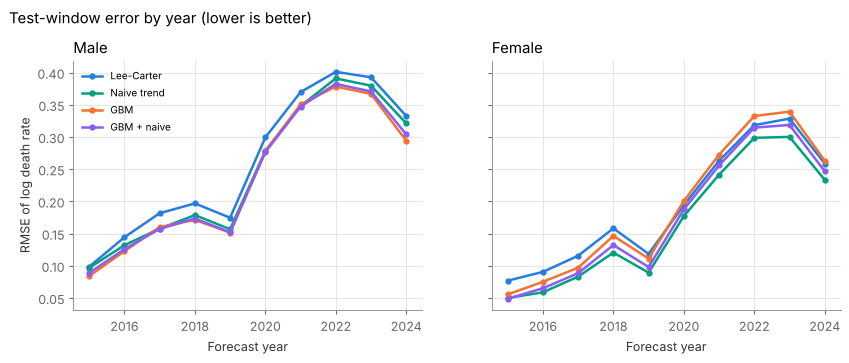

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, s in zip(axes, SEXES):
    for name, f in fc.items():
        e = error_by_year(test[s], f[s])
        ax.plot(e.index, e.values, marker="o", ms=4, color=MODEL_COLORS[name], label=name)
    ax.set_title(s.capitalize(), loc="left"); ax.set_xlabel("Forecast year")
axes[0].set_ylabel("RMSE of log death rate")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Test-window error by year (lower is better)", x=0.06, ha="left", y=1.04)
fig.savefig(f"{FIG_DIR}/ml_error_by_year.png", bbox_inches="tight", dpi=150)

**Results on the test window**
* **Men:** all three alternatives beat Lee-Carter. GBM has the lowest error over all ages (0.258 vs. 0.280 for Lee-Carter), but at ages 20–100 before the pandemic the naive trend is still best (0.122 vs. 0.134 for GBM).
* **Women:** the naive trend wins on every measure. GBM is worse than naive, and in 2020–2024 slightly worse than Lee-Carter. The blend lands in between.
* In both sexes, the differences between models are **small next to the jump in 2020**. That error comes from an event no model trained on 1980–2014 could know about.

Bottom line: gradient boosting did **not** reliably beat a one-line benchmark. That is a common result for mortality forecasting with a short series (35 years of training data), and it is the kind of result a model validator needs to see before trusting a more complex model.

## 5. Where are the errors? Bias by age band, 2015–2019

Average percentage error in death rates before the pandemic. **Negative = too optimistic** (forecast deaths too low; bad for term-life pricing). **Positive = too pessimistic.**

In [7]:
bands = [(0, 19), (20, 44), (45, 64), (65, 84), (85, 100)]
rows = []
for s in SEXES:
    for name, f in fc.items():
        diff = np.log(f[s].loc[:, :2019]) - np.log(test[s].loc[:, :2019])
        rows.append({"sex": s, "model": name,
                     **{f"{a}–{b}": (np.exp(diff.loc[a:b].to_numpy().mean()) - 1) * 100 for a, b in bands}})
bias = pd.DataFrame(rows).set_index(["sex", "model"]).round(1)
bias

0–19  20–44  45–64  65–84  85–100
sex    model                                         
male   Lee-Carter  -13.8  -21.3   -7.4   -0.8     6.0
       Naive trend -16.1  -17.3   -5.3   -2.0    -0.8
       GBM         -11.6  -18.9   -4.9   -3.1    -1.4
       GBM + naive -13.9  -18.1   -5.1   -2.6    -1.1
female Lee-Carter   -7.2  -14.3    2.2    3.3     6.6
       Naive trend  -5.8   -9.2   -2.6   -2.2    -0.6
       GBM         -10.6  -11.2   -2.4   -3.1    -1.3
       GBM + naive  -8.2  -10.2   -2.5   -2.7    -0.9

* **Every model is too optimistic at ages 20–44** (death rates forecast 9–21% too low). None of them could foresee the reversal at young-adult ages, because nothing like it appears in the 1980–2014 training data.
* At **ages 85+**, Lee-Carter is the outlier: 6–7% too pessimistic. The naive trend and GBM are within about 1.5%. For annuity and pension pricing, where old-age mortality matters most, that is a real advantage for the per-age models.
* GBM is the least biased model for **men at ages 0–19 and 45–64**, but it is no better than naive for women.

## 6. Life expectancy at birth: forecasts vs. actual

In [8]:
def e0_path(mx: pd.DataFrame, s: str) -> pd.Series:
    tail = q_all[s].loc[101:110, TRAIN_END].to_numpy()
    return pd.Series({y: e0(np.concatenate([mx_to_qx(mx[y]).to_numpy(), tail])) for y in mx.columns})

e0_tbl = {}
for s in SEXES:
    t = {"Actual": pd.Series({y: e0(q_all[s][y].to_numpy()) for y in range(2015, 2025)})}
    t.update({name: e0_path(f[s], s) for name, f in fc.items()})
    e0_tbl[s] = pd.DataFrame(t)
e0_view = pd.concat(e0_tbl, names=["sex", "year"]).loc[(slice(None), [2019, 2024]), :].round(2)
e0_view

Actual  Lee-Carter  Naive trend    GBM  GBM + naive
sex    year                                                     
male   2019   80.10       80.72        80.75  80.86        80.81
       2024   80.03       81.69        81.70  81.84        81.77
female 2019   84.32       84.07        84.55  84.65        84.60
       2024   84.29       84.66        85.17  85.29        85.23

* **Men, 2024:** every model forecast about 81.7–81.8 years against an actual 80.0. Model choice moves the answer by only 0.15 years; the shared miss is 1.7 years.
* **Women, 2024:** Lee-Carter happens to be closest (84.66 vs. actual 84.29), partly because its too-pessimistic old-age rates offset its too-optimistic young-adult rates. That is a good reason to check age bands and not only one summary number.

## 7. What is the model paying attention to?

**Permutation importance** shuffles one input at a time and measures how much worse the predictions get. I compute it for the model trained up to 2004, on rows whose target years are 2005–2014. The model never saw those targets.

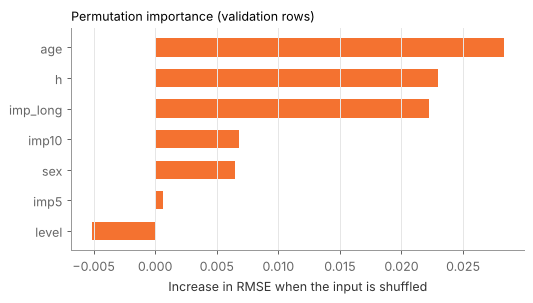

age         0.0283
h           0.0229
imp_long    0.0222
imp10       0.0068
sex         0.0065
imp5        0.0007
level      -0.0052
dtype: float64

In [9]:
from src.ml import build_training_set
Xv, yv = build_training_set({s: log_m[s].loc[:, :2014] for s in SEXES}, first_origin=VAL_ORIGIN, last_year=2014)
pi = permutation_importance(g_chosen.model, Xv[FEATURES], yv, n_repeats=10, random_state=0,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(imp.index, imp.values, color=MODEL_COLORS["GBM"], height=0.6)
ax.set_xlabel("Increase in RMSE when the input is shuffled")
ax.set_title("Permutation importance (validation rows)", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
fig.savefig(f"{FIG_DIR}/ml_permutation_importance.png", bbox_inches="tight", dpi=150)
imp.sort_values(ascending=False).round(4)

* The model relies mostly on **age**, the **horizon** and the **long-run improvement since 1980**.
* **Recent improvement** (`imp5`) barely matters. That explains the result: the model learned that the long-run trend predicts the future better than the last five years, which was true in the training data. But it means the model is slow to react when a trend genuinely breaks, as it did for young adults after 2010.
* Shuffling `level` slightly *improves* the score, so the model picked up some noise from it. Removing it is a reasonable next experiment, though a version without `level` scored slightly worse in validation, so it needs testing rather than assuming.

## 8. Conclusions

1. **Framing matters more than the algorithm.** A tree model on (age, year, sex) can't forecast at all. Reframed as "predict the change over *h* years", gradient boosting becomes a reasonable forecaster.
2. **ML helped for men, not for women.** Against a naive per-age trend, gradient boosting was slightly better for men over all ages and worse for women. Lee-Carter was the weakest of the three on average error.
3. **The largest risk is a broken trend, not the choice of model.** All models were 9–21% too optimistic for young adults and missed male life expectancy in 2024 by about 1.7 years. A better algorithm trained on the same history would not fix that. It needs scenario testing, cause-of-death information, or judgement about the overdose crisis.
4. **Model-risk view (OSFI E-23).** The validation discipline here (a separate validation window, a simple benchmark, error by age band, feature importance) is what shows that the extra complexity of ML is not clearly justified for this task.

**Next:** `04_insurance_pricing.ipynb`: price 10-year term life policies under each forecast, to show what these differences mean in dollars.